## Idea

I want to asses whether the proposed architecture from Martijn et al. is a sound way to reconstruct missing data for systems with dynamics that follow a predictable pattern.

This is a version that implements the techniques at a smallers sqale compared to what has implemented elsewhere in the repo, for demonstration purposes.

## Data

One minute of a single BIDMC record :

- **Patient 25, 45–105 s of the record.** The minute was picked by scanning the D1 training patients for 60 s windows with no ECG clipping, no flat PPG stretches and a stable PPG amplitude; of the windows that passed, this one had the most regular beats in both channels.
- **125 Hz, two channels:** ECG lead II (`ecg`) and PPG (`ppg`, PLETH). The demos fill gaps in one channel; the other can act as the helper.
- **Split of the minute:**
  - the first 40 s are the **history**. The recurrence fill searches it for donors;
  - the last 20 s are the **demo window**. Gaps will be cut there, and every method is scored on it.

  Bousse et al.'s completion uses only the demo window: their method needs no history.
- **Scaling:** both channels are z-scored with the mean and standard deviation of the history only, as in D1, so the demo window does not leak into the scaling.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FS = 125 # native dataset hz rate
START_S = 45 # clean, regular minute (see markdown above)
history_split = 40       # library for the recurrence fill
demo_split = 20          # window where gaps are cut and scored

raw = pd.read_csv("../../data/raw/bidmc/bidmc_25_Signals.csv")
raw.columns = [c.strip() for c in raw.columns]   # BIDMC headers have leading spaces

i0 = START_S * FS
n_hist, n_demo = history_split * FS, demo_split * FS
chunk = raw.iloc[i0 : i0 + n_hist + n_demo]
t = chunk["Time [s]"].to_numpy()
x_raw = chunk[["II", "PLETH"]].to_numpy(float)   # columns: 0 = ECG, 1 = PPG
assert len(x_raw) == 7500 and t[0] == 45.0 and t[-1] == 104.99 and np.isfinite(x_raw).all()

In [7]:
# z-score with the history only
mu, sd = x_raw[:n_hist].mean(axis=0), x_raw[:n_hist].std(axis=0)
x = (x_raw - mu) / sd
ecg, ppg = x[:, 0], x[:, 1]

hist = slice(0, n_hist)
demo = slice(n_hist, n_hist + n_demo)
print(f"patient 25: {len(x)} samples = {len(x) / FS:.0f} s at {FS} Hz "
      f"({t[0]:.0f}-{t[-1]:.0f} s of the record)")
print(f"history: {n_hist} samples, demo window: {n_demo} samples")

patient 25: 7500 samples = 60 s at 125 Hz (45-105 s of the record)
history: 5000 samples, demo window: 2500 samples


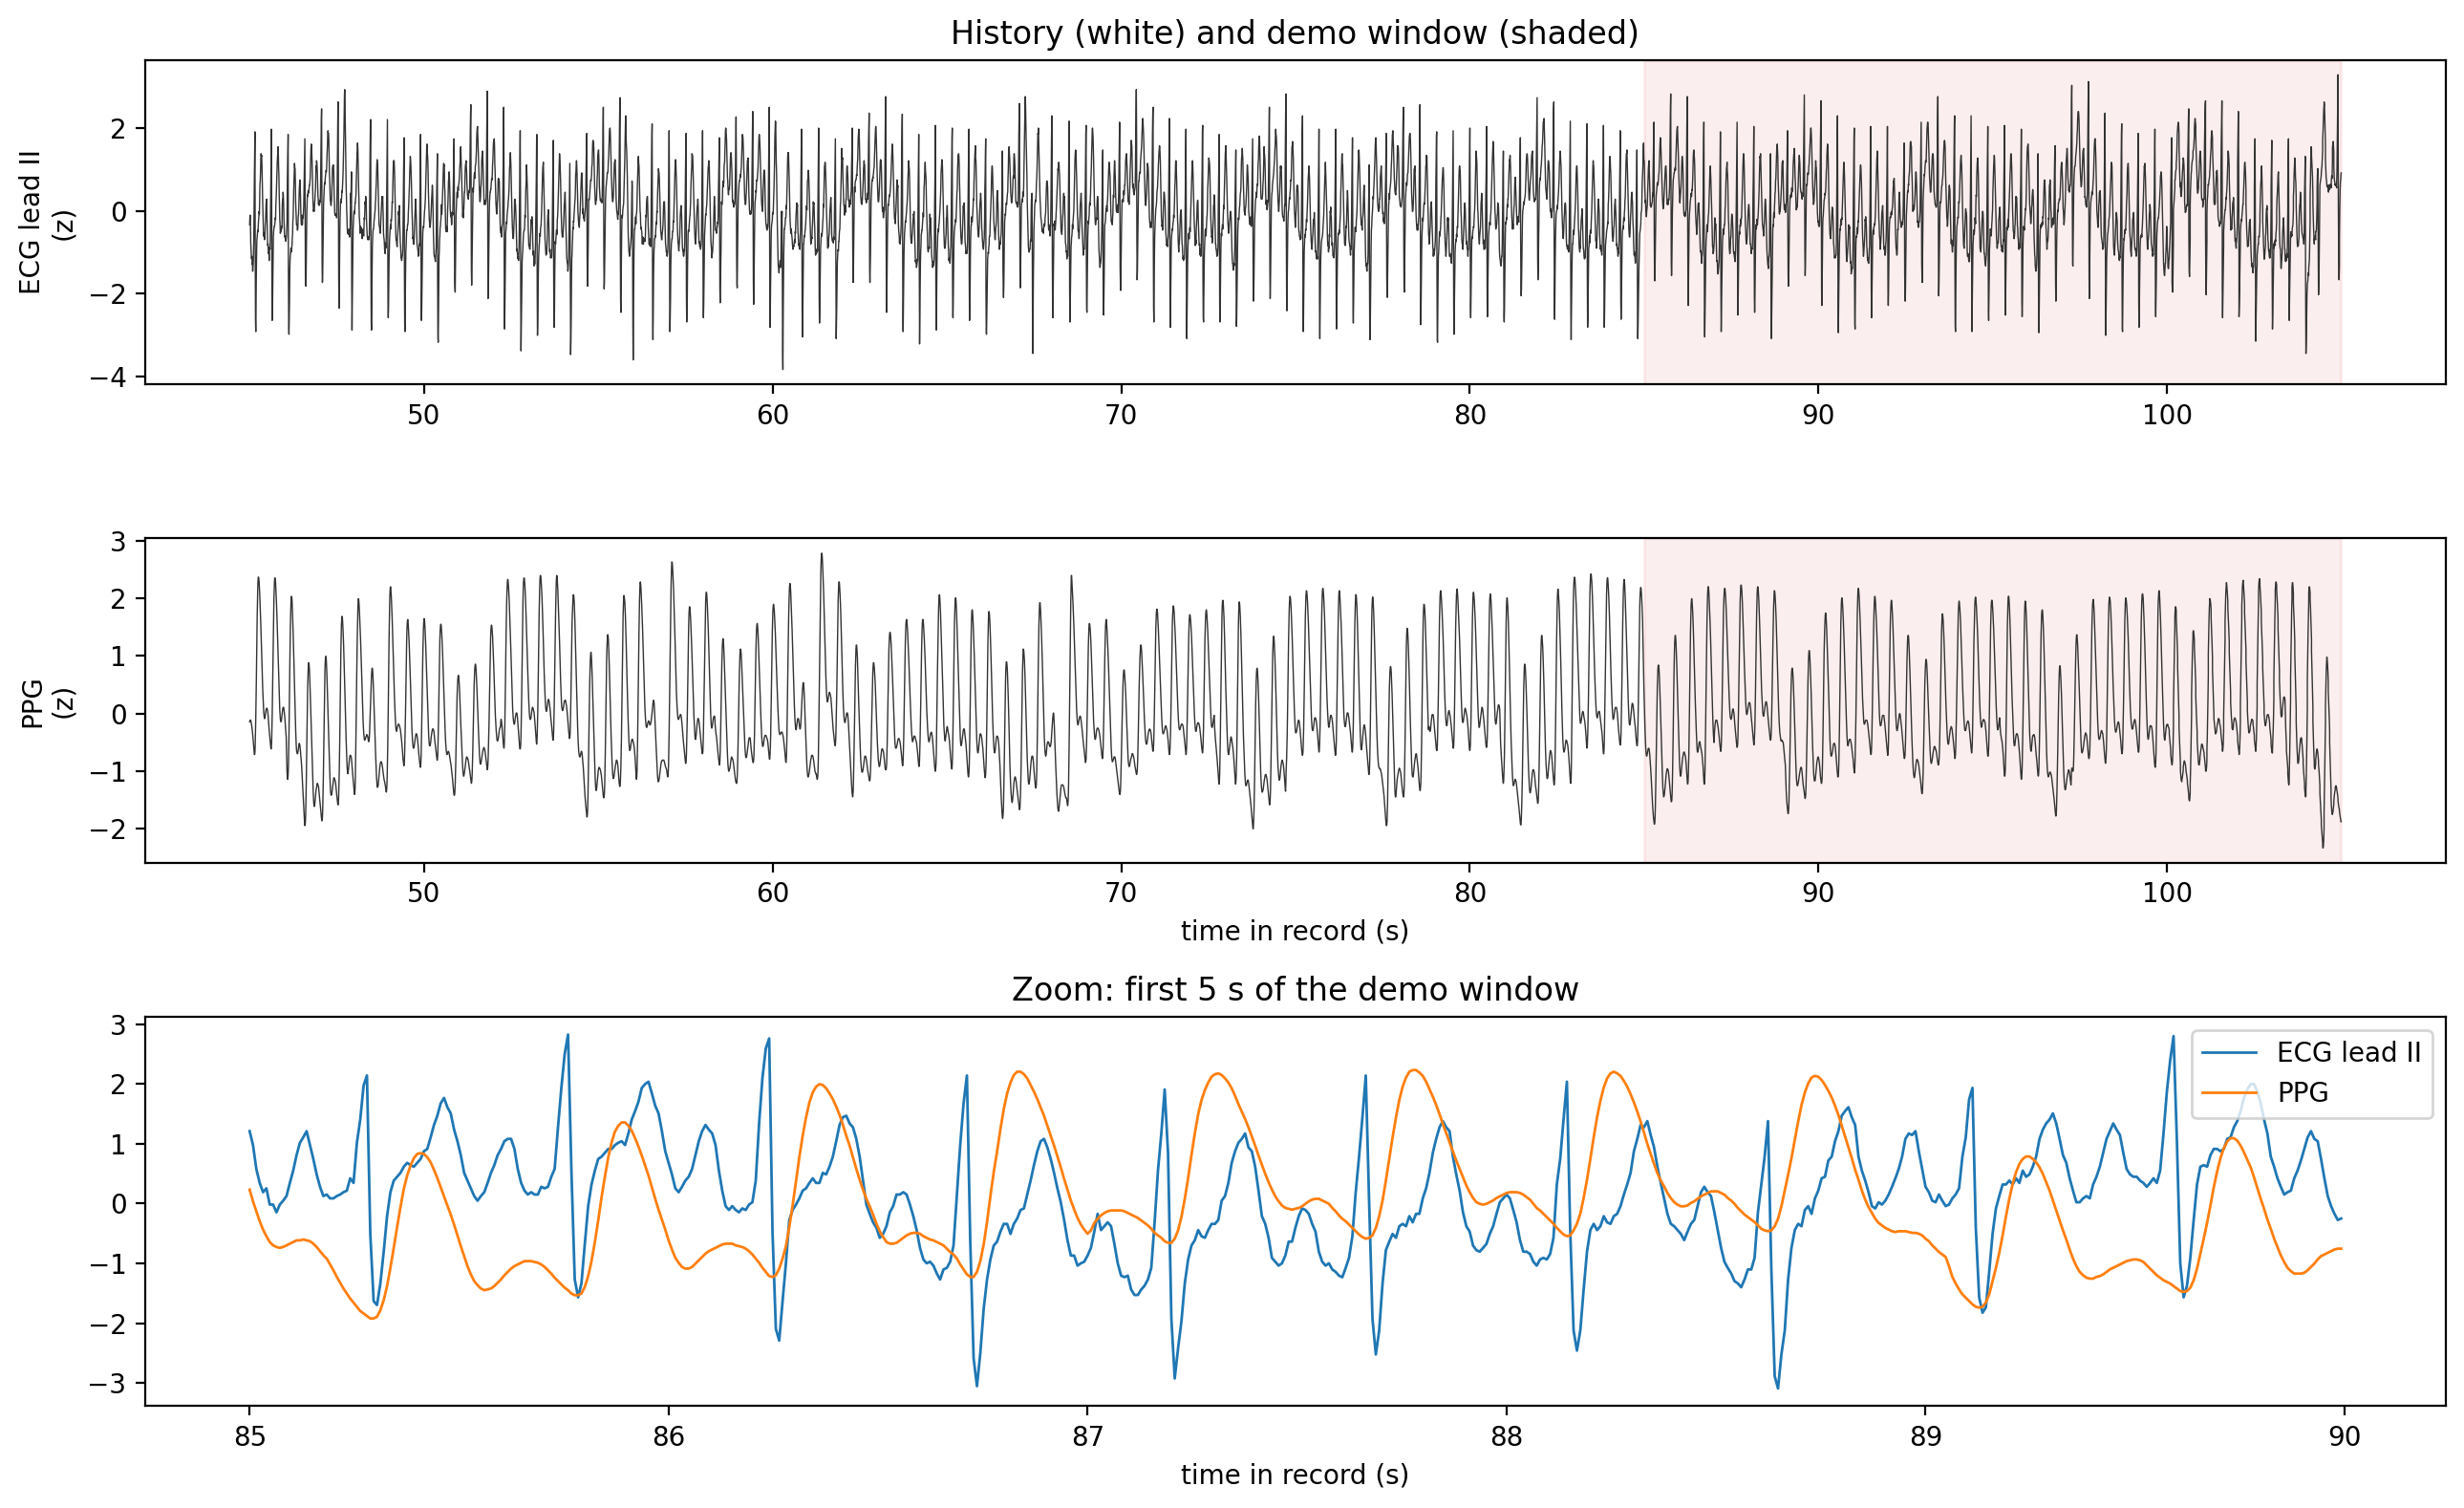

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), gridspec_kw={"height_ratios": [1, 1, 1.2]})
for ax, sig, name in [(axes[0], ecg, "ECG lead II"), (axes[1], ppg, "PPG")]:
    ax.plot(t, sig, lw=0.5, color="0.2")
    ax.axvspan(t[demo][0], t[-1], color="tab:red", alpha=0.08)
    ax.set_ylabel(f"{name}\n(z)")
axes[0].set_title("History (white) and demo window (shaded)")
axes[1].set_xlabel("time in record (s)")

# 5 s zoom at the start of the demo window: ECG and PPG together
z = slice(n_hist, n_hist + 5 * FS)
axes[2].plot(t[z], ecg[z], lw=1, label="ECG lead II")
axes[2].plot(t[z], ppg[z], lw=1, label="PPG")
axes[2].set_title("Zoom: first 5 s of the demo window")
axes[2].set_xlabel("time in record (s)")
axes[2].legend(loc="upper right")
fig.tight_layout()
plt.show()

In [9]:
# Gaps are cut in one channel only; the other channel stays complete (helper).
target = 0   # 0 = ECG, 1 = PPG

# (start, length) in samples, counted from the start of the demo window.
# Lengths 25 and 75 are the D1 ECG gap lengths (0.2 s and 0.6 s).
# All gaps stay at least 125 samples (1 s) away from the window edges.
gaps = [(300, 25), (800, 75), (1400, 25), (1900, 75)]

In [10]:
x_obs = x.copy()
missing = np.zeros(len(x), dtype=bool)

for start, length in gaps:
    a = n_hist + start
    b = a + length
    missing[a:b] = True

x_obs[missing, target] = np.nan

print(f"removed {missing.sum()} samples of channel {target} "
      f"({missing.sum() / n_demo:.1%} of the demo window)")

removed 200 samples of channel 0 (8.0% of the demo window)


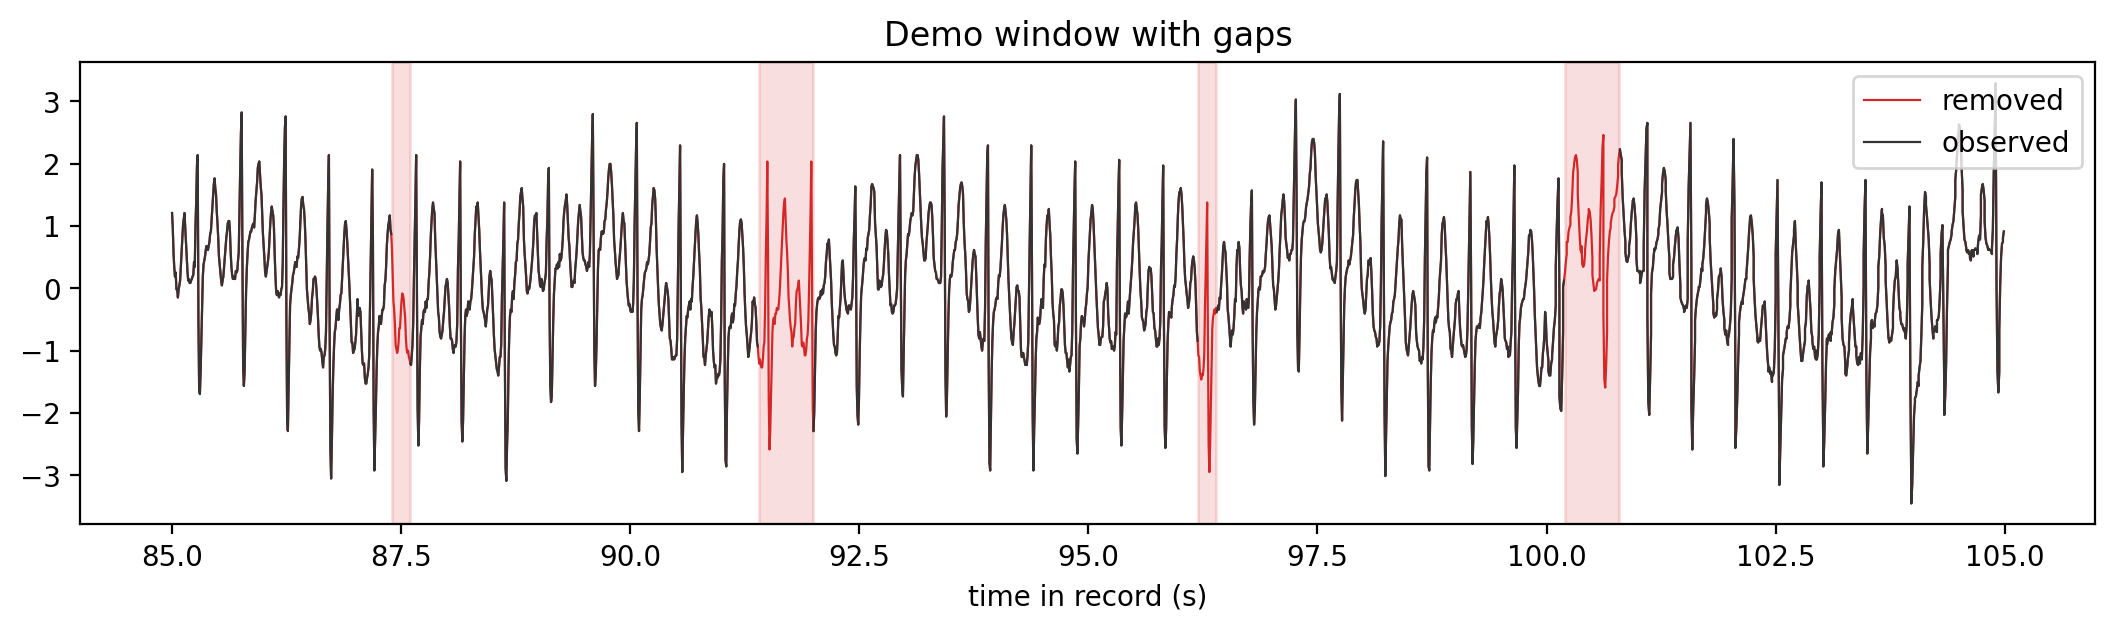

In [12]:
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(t[demo], x[demo, target], color="tab:red", lw=0.8, label="removed")
ax.plot(t[demo], x_obs[demo, target], color="0.2", lw=0.8, label="observed")
for start, length in gaps:
    ax.axvspan(t[n_hist + start], t[n_hist + start + length - 1], color="tab:red", alpha=0.15)
ax.set_title("Demo window with gaps")
ax.set_xlabel("time in record (s)")
ax.legend(loc="upper right")
plt.show()

In [13]:
from scipy.spatial.distance import cdist

# RP embedding used to score every method
RP_M, RP_TAU = 5, 8

def embed(v, m=RP_M, tau=RP_TAU):
    n = len(v) - (m - 1) * tau
    return np.column_stack([v[k * tau : k * tau + n] for k in range(m)])

def unthresholded_rp(v):
    e = embed(v)
    return cdist(e, e)

In [14]:
truth = x[demo, target]
gap_mask = missing[demo]
rp_truth = unthresholded_rp(truth)

results = {}

def score(name, filled):
    mae = np.abs(filled[gap_mask] - truth[gap_mask]).mean()
    rp_err = np.linalg.norm(unthresholded_rp(filled) - rp_truth) / np.linalg.norm(rp_truth)
    results[name] = {"MAE": mae, "RP error": rp_err}
    
    print(f"{name}: MAE {mae:.3f}, RP error {rp_err:.4f}")

In [17]:
obs = x_obs[demo, target] # demo window with NaN in the gaps
idx = np.arange(n_demo)
known = ~np.isnan(obs)

linear_fill = obs.copy()
linear_fill[~known] = np.interp(idx[~known], idx[known], obs[known])

score("linear", linear_fill)

linear: MAE 1.003, RP error 0.1700


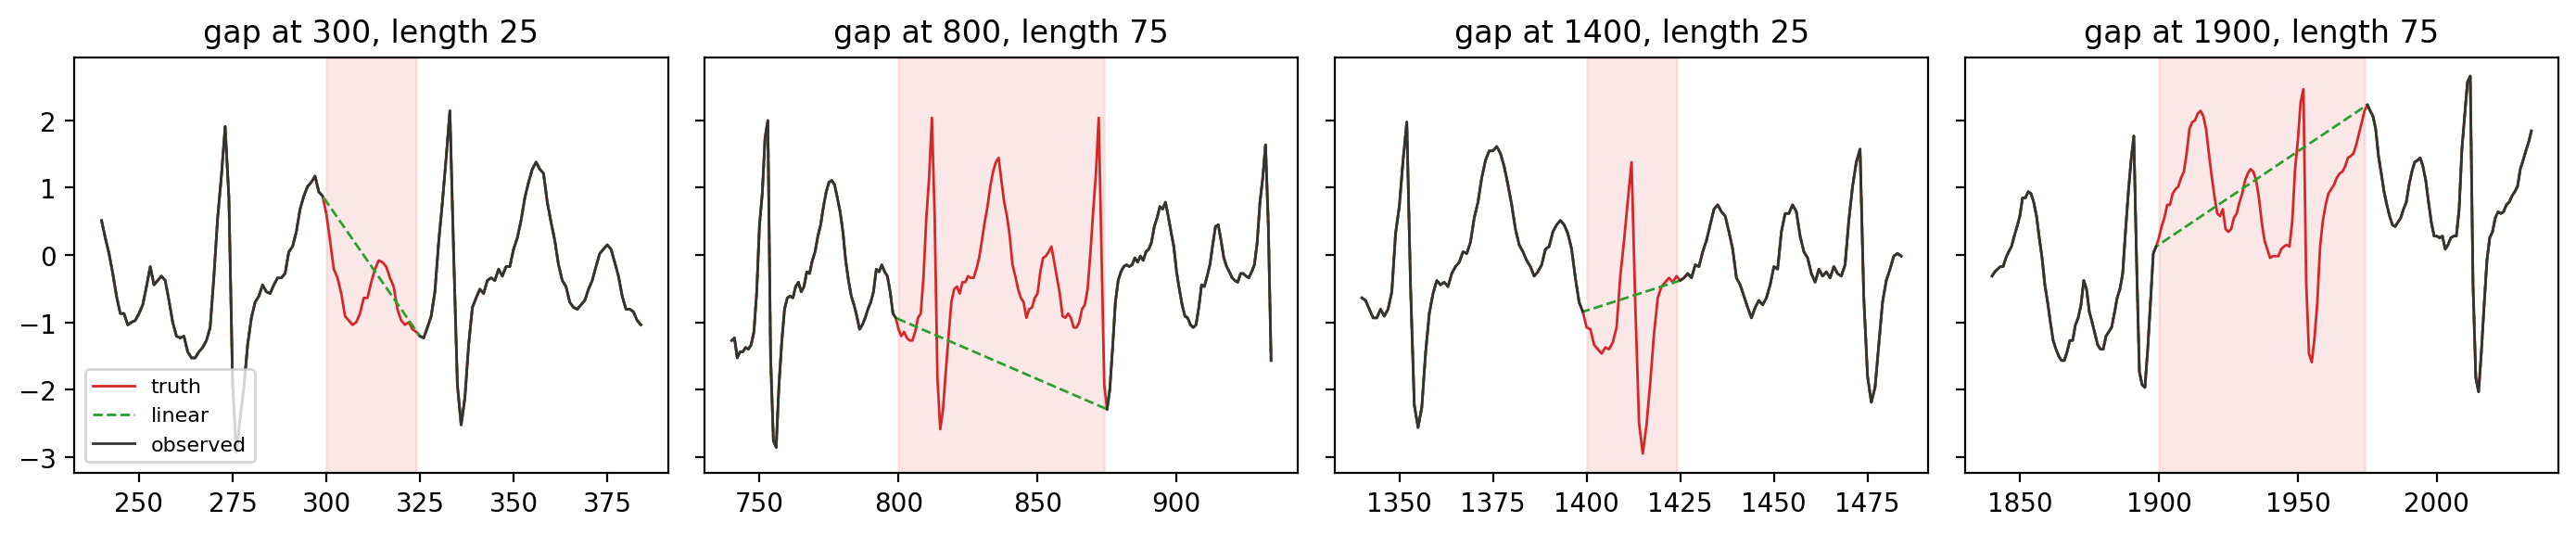

In [18]:
fig, axes = plt.subplots(1, len(gaps), figsize=(14, 3), sharey=True)
for ax, (start, length) in zip(axes, gaps):
    w = slice(start - 60, start + length + 60)   # gap plus 60 samples each side
    ax.plot(idx[w], truth[w], color="tab:red", lw=1, label="truth")
    ax.plot(idx[w], linear_fill[w], color="tab:green", lw=1, ls="--", label="linear")
    ax.plot(idx[w], obs[w], color="0.2", lw=1, label="observed")
    ax.axvspan(start, start + length - 1, color="tab:red", alpha=0.1)
    ax.set_title(f"gap at {start}, length {length}")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

In [21]:
from scipy.interpolate import CubicSpline

spline_fill = obs.copy()
spline_fill[~known] = CubicSpline(idx[known], obs[known])(idx[~known])

score("spline", spline_fill)

spline: MAE 1.661, RP error 0.3915


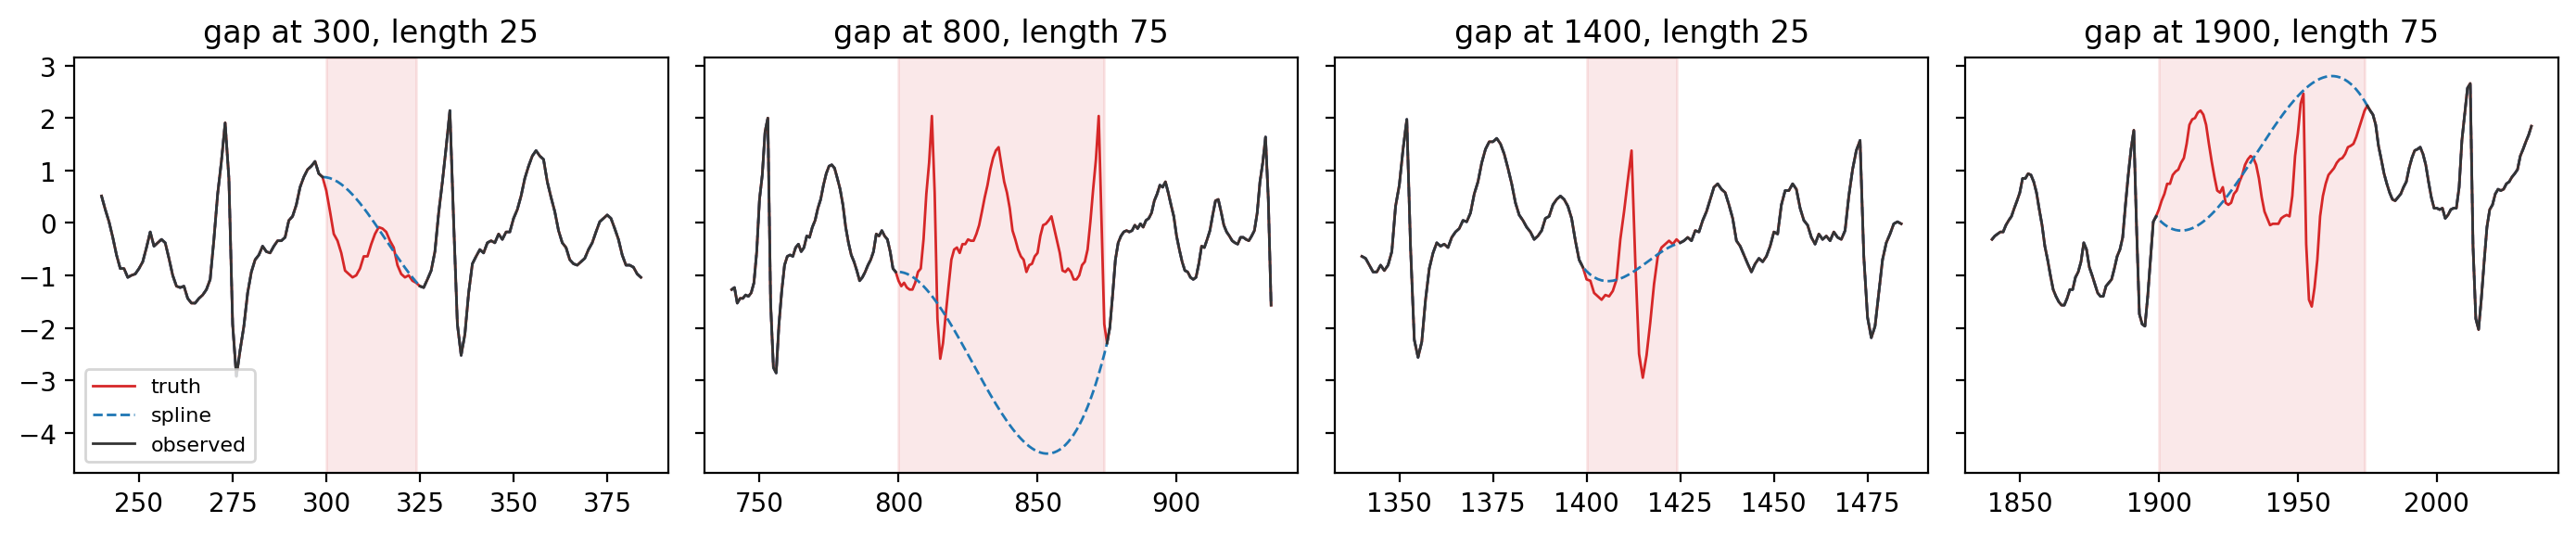

In [22]:
fig, axes = plt.subplots(1, len(gaps), figsize=(14, 3), sharey=True)
for ax, (start, length) in zip(axes, gaps):
    w = slice(start - 60, start + length + 60)   # gap plus 60 samples each side
    ax.plot(idx[w], truth[w], color="tab:red", lw=1, label="truth")
    ax.plot(idx[w], spline_fill[w], color="tab:blue", lw=1, ls="--", label="spline")
    ax.plot(idx[w], obs[w], color="0.2", lw=1, label="observed")
    ax.axvspan(start, start + length - 1, color="tab:red", alpha=0.1)
    ax.set_title(f"gap at {start}, length {length}")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

In [23]:
# Completion embedding: their ECG setting (M = 50, tau = 1). It is separate from the RP embedding used for scoring.
M_C, TAU_C = 50, 1

def hankel(v, M=M_C, tau=TAU_C):
    # Embedding matrix: 
    # row i = (v_i, v_i+tau, ..., v_i+(M-1)tau)
    n = len(v) - (M - 1) * tau
    return np.column_stack([v[k * tau : k * tau + n] for k in range(M)])

X = hankel(obs)
K = ~np.isnan(X)   # True on known entries
print(f"X: {X.shape[0]} rows x {X.shape[1]} columns, {(~K).sum()} missing entries, "
      f"{(~K).any(axis=1).sum()} rows with at least one missing entry")

X: 2451 rows x 50 columns, 10000 missing entries, 396 rows with at least one missing entry


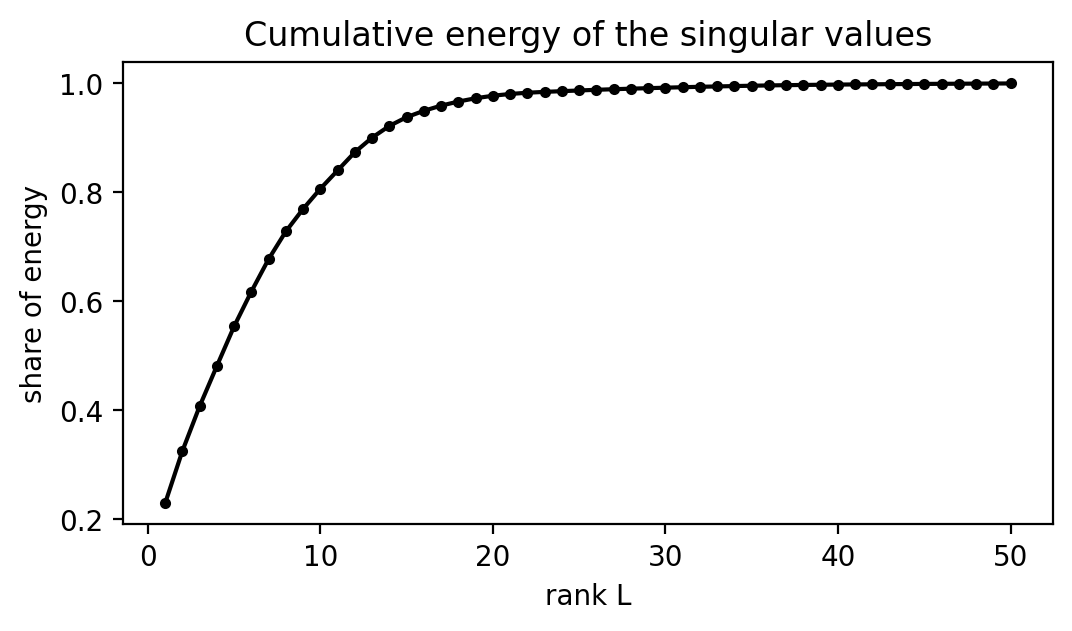

rank needed for 90 / 95 / 99 % of the energy: [13, 17, 28]


In [24]:
# How low-rank is the ECG? 
# Singular values of the rows with no missing entry.
s = np.linalg.svd(X[K.all(axis=1)], compute_uv=False)
energy = np.cumsum(s**2) / np.sum(s**2)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, len(s) + 1), energy, "k.-")
ax.set_xlabel("rank L")
ax.set_ylabel("share of energy")
ax.set_title("Cumulative energy of the singular values")
plt.show()
print("rank needed for 90 / 95 / 99 % of the energy:",
      [int(np.searchsorted(energy, q) + 1) for q in (0.90, 0.95, 0.99)])

In [29]:
def fit_low_rank(X, K, L, lam=1.0, n_iter=30, seed=0):
    rng = np.random.default_rng(seed)
    A = np.zeros((X.shape[0], L))
    B = rng.standard_normal((X.shape[1], L))
    I = lam * np.eye(L)
    for _ in range(n_iter):
        for i in range(X.shape[0]):
            k = K[i]
            A[i] = np.linalg.solve(B[k].T @ B[k] + I, B[k].T @ X[i, k])
        for j in range(X.shape[1]):
            k = K[:, j]
            B[j] = np.linalg.solve(A[k].T @ A[k] + I, A[k].T @ X[k, j])
    return A, B

In [26]:
L = 8
A, B = fit_low_rank(X, K, L)
X_filled = np.where(K, X, A @ B.T)   # known entries kept, missing ones from the model

print("fit error on the known entries:",
      np.sqrt(np.mean((A @ B.T - X)[K] ** 2)).round(3))

fit error on the known entries: 0.523


In [27]:
# Bousse et al. build the RP directly from X_filled. To score every method with the same RP,
# we turn X_filled back into a series: each missing sample appears once in every row that
# contains it, and we average those copies.
total = np.zeros(n_demo)
count = np.zeros(n_demo)
rows = np.arange(X.shape[0])
for k in range(M_C):
    total[rows + k * TAU_C] += X_filled[:, k]
    count[rows + k * TAU_C] += 1

bousse_fill = obs.copy()
bousse_fill[~known] = total[~known] / count[~known]

score("bousse", bousse_fill)

bousse: MAE 0.824, RP error 0.1421


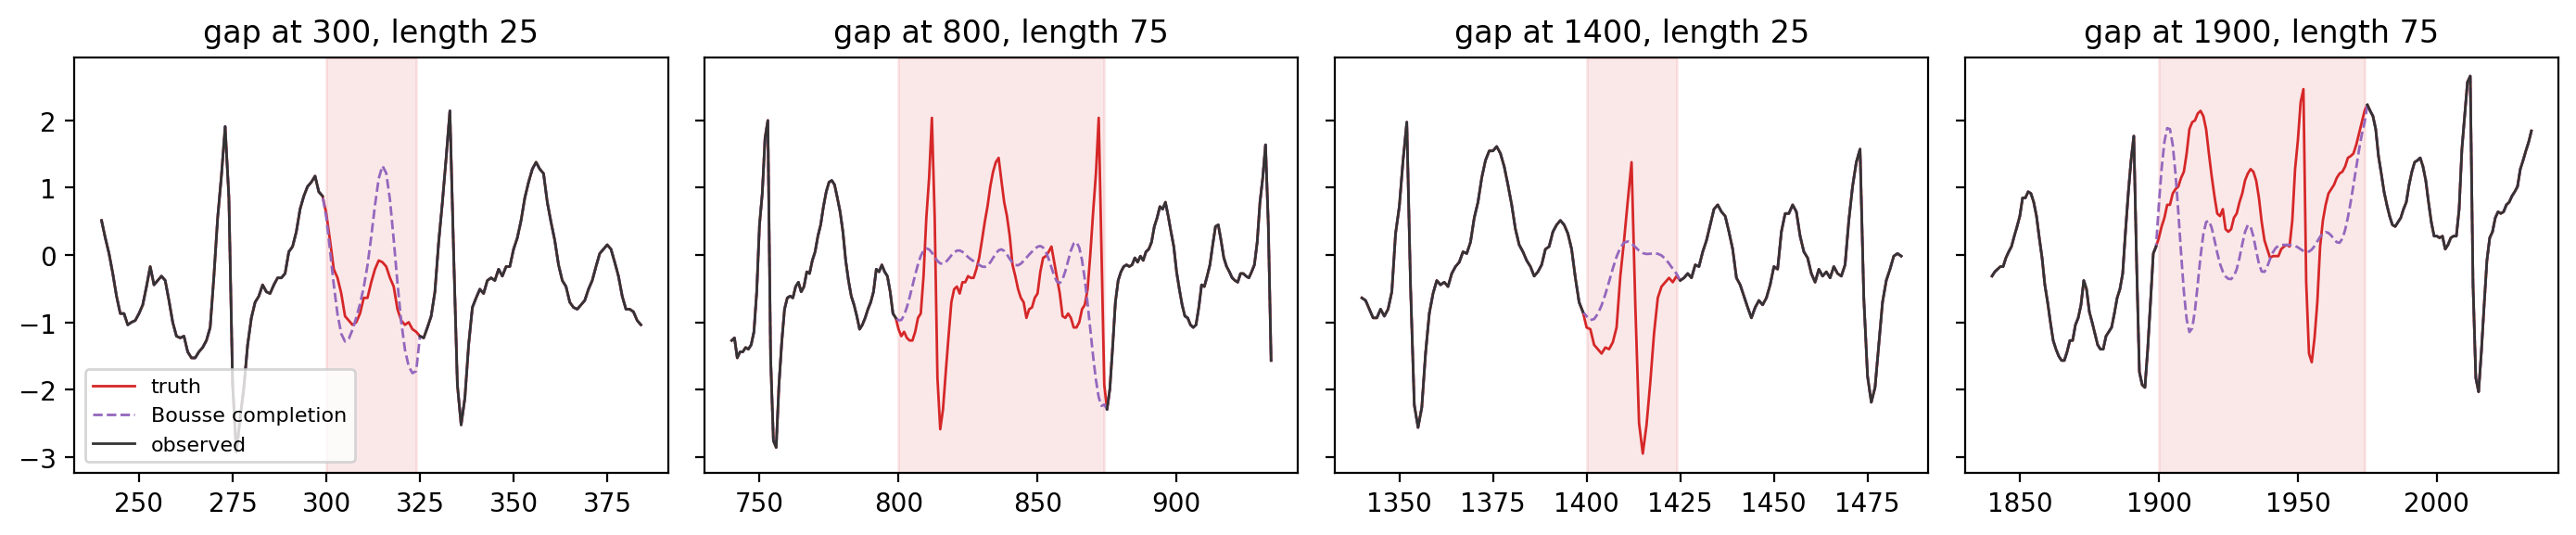

In [28]:
fig, axes = plt.subplots(1, len(gaps), figsize=(14, 3), sharey=True)
for ax, (start, length) in zip(axes, gaps):
    w = slice(start - 60, start + length + 60)   # gap plus 60 samples each side
    ax.plot(idx[w], truth[w], color="tab:red", lw=1, label="truth")
    ax.plot(idx[w], bousse_fill[w], color="tab:purple", lw=1, ls="--", label="Bousse completion")
    ax.plot(idx[w], obs[w], color="0.2", lw=1, label="observed")
    ax.axvspan(start, start + length - 1, color="tab:red", alpha=0.1)
    ax.set_title(f"gap at {start}, length {length}")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

In [30]:
from numpy.lib.stride_tricks import sliding_window_view

C = 25 # context samples on each side of a gap (one value of D1's ECG grid 12, 25, 62, 125)
N_DONORS = 8

library = x[hist]        # complete history, both channels: the patient's own past
query_series = x_obs[demo]   # demo window, NaN in the target channel's gaps

In [31]:
def recurrence_fill(query_series, library, channels, C=C, k=N_DONORS):
    # Fill each gap of the target channel with the weighted mean of the k library windows
    # whose observed values best match the window [gap start - C, gap end + C).

    # channels: which columns take part in the matching (the target must be one of them).
    # Returns the filled demo window of the target channel and, per gap, the donors used.
    
    q_all = query_series[:, channels]
    lib = library[:, channels]
    col = channels.index(target)
    filled = query_series[:, target].copy()
    donors = {}
    for start, length in gaps:
        a, b = start - C, start + length + C
        q = q_all[a:b].T                                        # (channels, window), NaN in the gap
        cand = sliding_window_view(lib, b - a, axis=0)          # (library windows, channels, window)
        d = np.nanmean((cand - q) ** 2, axis=(1, 2))            # mean sq. difference on observed entries
        nn = np.argsort(d)[:k]                                  # k nearest library windows
        w = np.exp(-d[nn] / d[nn].min())
        segs = cand[nn, col, C : C + length]                    # what each donor has where the gap is
        filled[start : start + length] = (w[:, None] * segs).sum(axis=0) / w.sum()
        donors[start] = {"starts": nn, "dist": d, "weights": w / w.sum(), "segments": segs}
    return filled, donors

In [32]:
# Matching on the target channel only (context before and after the gap)
rec_own_fill, donors_own = recurrence_fill(query_series, library, channels=[target])
score("recurrence (own channel)", rec_own_fill)

# Matching on both channels: the other channel is observed inside the gap too
rec_both_fill, donors_both = recurrence_fill(query_series, library, channels=[0, 1])
score("recurrence (+ helper)", rec_both_fill)

recurrence (own channel): MAE 0.368, RP error 0.0703
recurrence (+ helper): MAE 0.316, RP error 0.0593


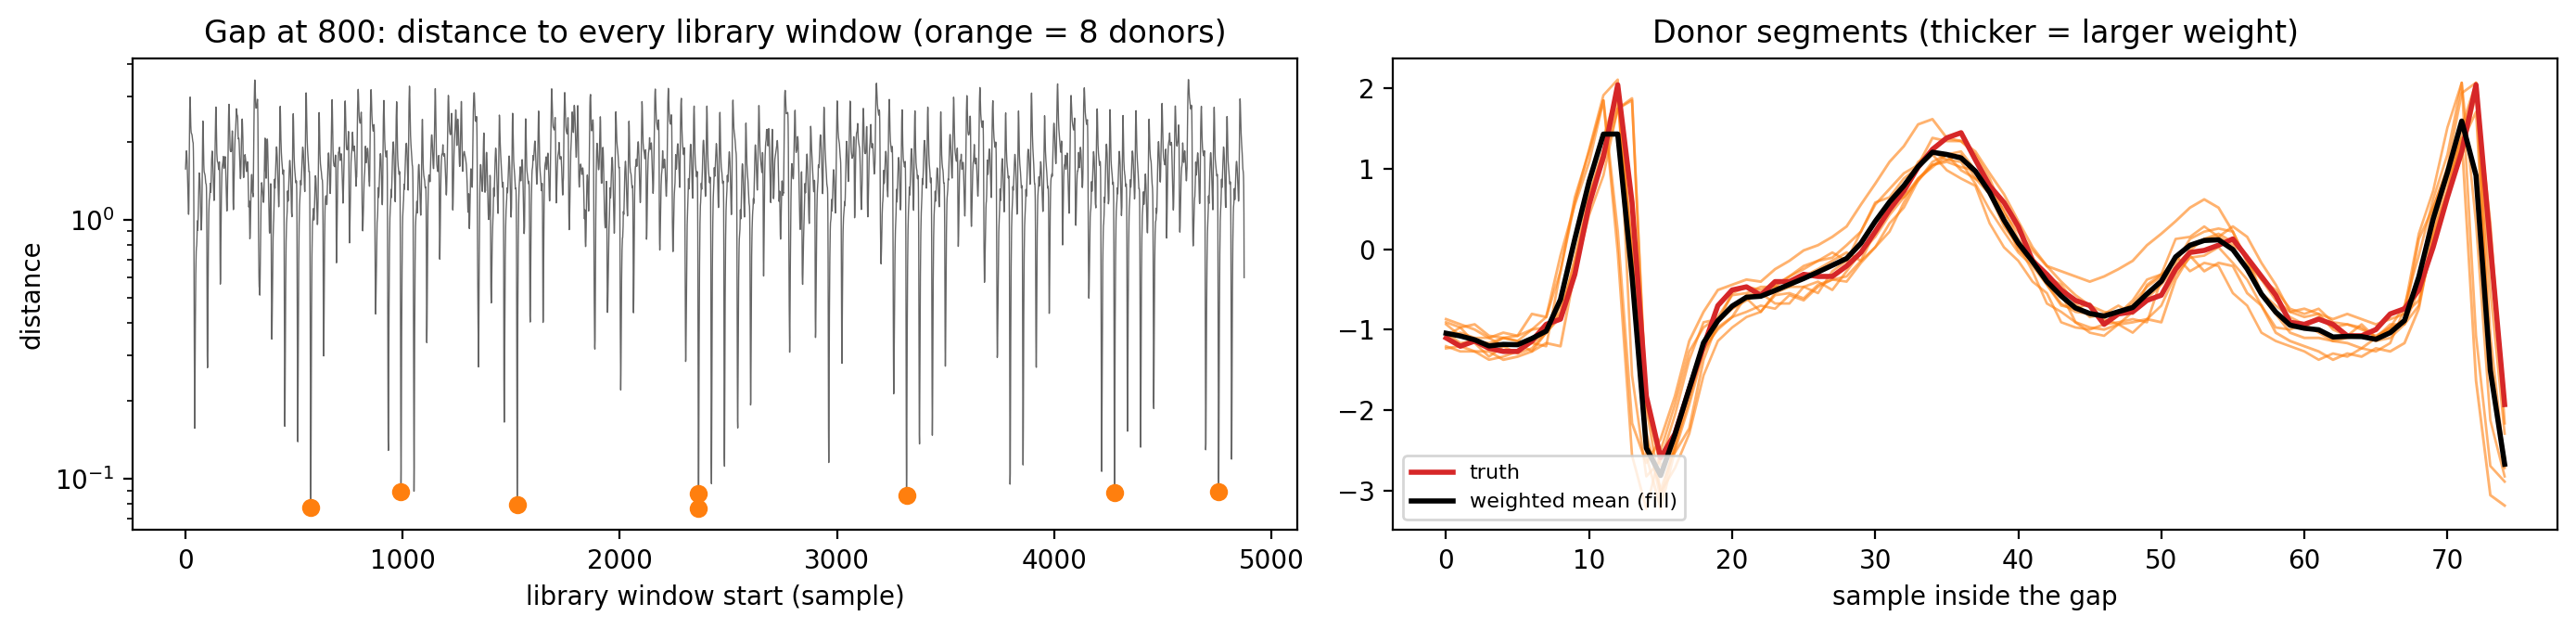

In [33]:
# One gap in detail: the distance to every library window, and the chosen donors
g_start, g_len = gaps[1]
info = donors_own[g_start]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].plot(info["dist"], lw=0.5, color="0.4")
axes[0].plot(info["starts"], info["dist"][info["starts"]], "o", color="tab:orange")
axes[0].set_yscale("log")
axes[0].set_xlabel("library window start (sample)")
axes[0].set_ylabel("distance")
axes[0].set_title(f"Gap at {g_start}: distance to every library window (orange = {N_DONORS} donors)")

for seg, wt in zip(info["segments"], info["weights"]):
    axes[1].plot(seg, color="tab:orange", lw=0.5 + 4 * wt, alpha=0.6)
axes[1].plot(truth[g_start : g_start + g_len], color="tab:red", lw=2, label="truth")
axes[1].plot(rec_own_fill[g_start : g_start + g_len], "k", lw=2, label="weighted mean (fill)")
axes[1].set_xlabel("sample inside the gap")
axes[1].set_title("Donor segments (thicker = larger weight)")
axes[1].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

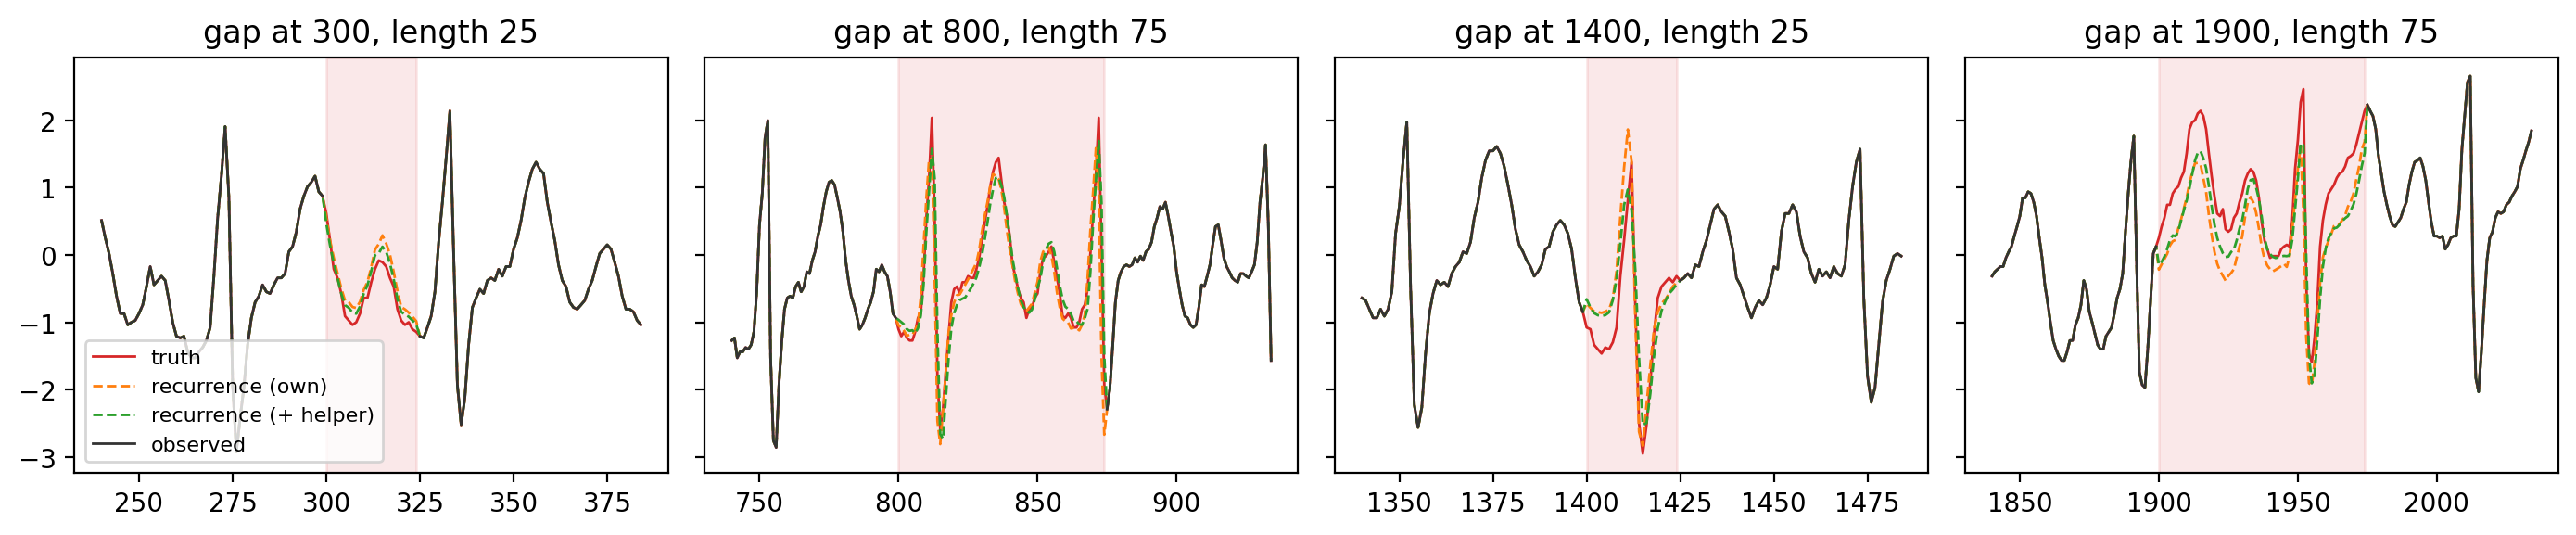

In [34]:
fig, axes = plt.subplots(1, len(gaps), figsize=(14, 3), sharey=True)
for ax, (start, length) in zip(axes, gaps):
    w = slice(start - 60, start + length + 60)   # gap plus 60 samples each side
    ax.plot(idx[w], truth[w], color="tab:red", lw=1, label="truth")
    ax.plot(idx[w], rec_own_fill[w], color="tab:orange", lw=1, ls="--", label="recurrence (own)")
    ax.plot(idx[w], rec_both_fill[w], color="tab:green", lw=1, ls="--", label="recurrence (+ helper)")
    ax.plot(idx[w], obs[w], color="0.2", lw=1, label="observed")
    ax.axvspan(start, start + length - 1, color="tab:red", alpha=0.1)
    ax.set_title(f"gap at {start}, length {length}")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

In [35]:
pd.DataFrame(results).T.round(3)

,MAE,RP error
spline,1.661,0.391
linear,1.003,0.170
bousse,0.824,0.142
recurrence (own channel),0.368,0.070
recurrence (+ helper),0.316,0.059
